# Decoding strategies: greedy vs. beam search vs. nucleus sampling

This notebook takes the trained **ClipCap prototype** from `Sample_Test_Runs_ClipCap.ipynb` (CLIP ViT-B/32 → mapping MLP → 10 prefix vectors → fine-tuned GPT-2) and compares how it **decodes** a caption from the same image prefix. Nothing is retrained: it loads the saved checkpoint.

| Strategy | How the next token is chosen |
|---|---|
| **greedy** | always the single most likely token |
| **beam-3 / beam-5** | keeps the 3 / 5 most likely partial captions at each step and returns the best one; repeated 3-grams blocked (same settings as the baseline run) |
| **nucleus (p=0.9, T=0.7 / 1.0)** | samples from the smallest set of tokens whose probability adds up to 90%; temperature T < 1 sharpens the distribution |

It produces the milestone deliverables:
1. the **training log** and loss curve of the prototype (recovered from the checkpoint),
2. **10 test images** captioned with every strategy,
3. a **quantitative comparison** on the Karpathy test split: BLEU-1/4 and CIDEr against the 5 human captions, CLIP image–caption similarity, caption length, diversity, repetition and speed.

**Prerequisite:** `outputs/clipcap_prototype/clipcap_mlp_gpt2.pt` from `Sample_Test_Runs_ClipCap.ipynb`. On Colab it is already on Drive in `MyDrive/image-captioning/`.

**On Colab:**
1. *Runtime → Change runtime type → T4 GPU*.
2. Connect Google Drive **before** running anything: click the folder icon in the left sidebar, then the *Mount Drive* icon (folder with the Drive logo). Wait until a `drive` folder appears. (Or run the next cell on its own; in the sign-in window, pick the account that owns `MyDrive/image-captioning` and tick **every** permission box. If you leave any unticked, the mount fails and Colab asks again.)
3. *Runtime → Run all* (about 10–15 min, mostly the test-set evaluation).

In [1]:
# Colab only: connect Google Drive (skipped if it is already connected via the sidebar's "Mount Drive" button)
import sys, os
if "google.colab" in sys.modules and not os.path.isdir("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)
print("Drive connected:", os.path.isdir("/content/drive/MyDrive"))

Drive connected: False


In [2]:
import os, sys, re, time, random, textwrap
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from transformers import GPT2LMHeadModel, GPT2TokenizerFast, CLIPModel, CLIPProcessor

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install "transformers>=4.44" pycocoevalcap
    assert os.path.isdir("/content/drive/MyDrive"), "Google Drive is not connected: run the cell above first"
PROJECT_DIR = Path("/content/drive/MyDrive/image-captioning") if IN_COLAB else Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data" / "flickr30k_subset", PROJECT_DIR / "outputs"
IMG_DIR = DATA_DIR / "images"
EMB_PATH, TOK_PATH = OUT_DIR / "clip_image_embeddings.pt", OUT_DIR / "gpt2_tokens.pt"
CKPT_PATH = OUT_DIR / "clipcap_prototype" / "clipcap_mlp_gpt2.pt"
RES_DIR = OUT_DIR / "decoding"
RES_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
SEED = 42
PREFIX_LEN = 10
MAX_NEW_TOKENS = 30
N_EVAL = int(os.environ.get("N_EVAL", 1000))          # test images scored per strategy (the full test split is 1,000)
GEN_BATCH = 50
ALLOW_UNTRAINED = os.environ.get("ALLOW_UNTRAINED") == "1"   # only for a quick test of the code without a checkpoint

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
BUNDLE = PROJECT_DIR / "colab_bundle.zip"
if BUNDLE.exists() and not EMB_PATH.exists():
    import zipfile
    zipfile.ZipFile(BUNDLE).extractall(PROJECT_DIR)
    print("unpacked", BUNDLE)
assert EMB_PATH.exists() and TOK_PATH.exists(), "run Image_Captioning_Baseline.ipynb first (or upload colab_bundle.zip)"
assert CKPT_PATH.exists() or ALLOW_UNTRAINED, f"missing {CKPT_PATH}: run Sample_Test_Runs_ClipCap.ipynb first"
print("device:", DEVICE, "| N_EVAL:", N_EVAL)

W1122 19:12:06.565000 39608 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


device: mps | N_EVAL: 1000


## 1. Data and the trained model

In [3]:
emb_file, tok_file = torch.load(EMB_PATH), torch.load(TOK_PATH)
IMAGE_EMB, IMAGE_IDS = emb_file["embeddings"], emb_file["image_ids"]   # [5000, 512], L2-normalised
emb_row = {iid: i for i, iid in enumerate(IMAGE_IDS)}
captions_df = pd.read_csv(DATA_DIR / "captions_clean.csv", dtype={"image_id": str})
test_refs = captions_df[captions_df.split == "test"].groupby("image_id").caption.apply(list).to_dict()

# Same test-image order as Sample_Test_Runs_ClipCap.ipynb, so the first 5 samples are the same images
is_test = torch.tensor([s == "test" for s in tok_file["split"]])
test_ids = sorted({IMAGE_IDS[i] for i in tok_file["image_index"][is_test].tolist()})
print(f"test images: {len(test_ids)} | with references: {len(test_refs)}")


class ClipCaptionModel(nn.Module):
    def __init__(self, prefix_len=PREFIX_LEN, clip_dim=512):
        super().__init__()
        self.gpt = GPT2LMHeadModel.from_pretrained("gpt2")
        d = self.gpt.config.n_embd
        self.prefix_len = prefix_len
        hidden = (clip_dim + d * prefix_len) // 2
        self.mapping = nn.Sequential(nn.Linear(clip_dim, hidden), nn.Tanh(), nn.Linear(hidden, d * prefix_len))

    def prefix(self, clip_embedding):
        return self.mapping(clip_embedding).view(-1, self.prefix_len, self.gpt.config.n_embd)


model = ClipCaptionModel()
if CKPT_PATH.exists():
    ckpt = torch.load(CKPT_PATH, map_location="cpu", weights_only=False)
    model.load_state_dict(ckpt["state_dict"])
    history = pd.DataFrame(ckpt["history"])
    print("loaded", CKPT_PATH)
else:
    history = None
    print("WARNING: no checkpoint, using an UNTRAINED mapping network (code test only)")
model = model.to(DEVICE).eval()
tokenizer = GPT2TokenizerFast.from_pretrained("gpt2")

test images: 1000 | with references: 1000


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

loaded /Users/garimadaryani/Documents/NEU/image-captioning-clip-gpt2/outputs/clipcap_prototype/clipcap_mlp_gpt2.pt


## 2. Training log

The per-epoch losses stored with the checkpoint (5 epochs, 14,907 train captions, AdamW with learning rates 1e-4 for the MLP and 3e-5 for GPT-2, linear warm-up then decay, batch size 32, Colab T4). The checkpoint keeps the epoch with the lowest validation loss.

,epoch,train_loss,val_loss,val_perplexity
0,1,3.027,2.577,13.2
1,2,2.461,2.517,12.4
2,3,2.300,2.491,12.1
3,4,2.189,2.492,12.1
4,5,2.111,2.503,12.2


best epoch: 3 (val loss 2.491, perplexity 12.1)


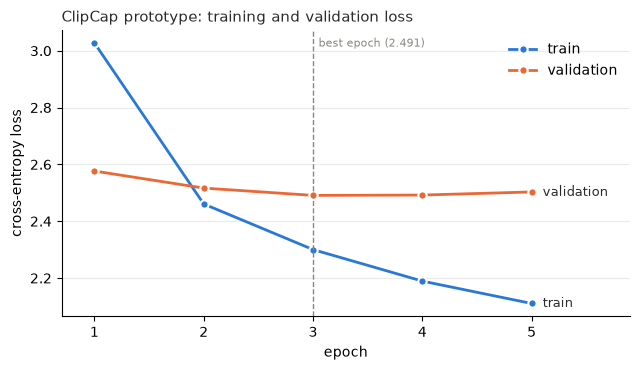

In [4]:
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#2b2b29", "#8a897f"

if history is not None:
    history["val_perplexity"] = np.exp(history.val_loss).round(1)
    best = history.loc[history.val_loss.idxmin()]
    history.round(3).to_csv(RES_DIR / "train_log.csv", index=False)
    display(history.round(3))
    print(f"best epoch: {int(best.epoch)} (val loss {best.val_loss:.3f}, perplexity {best.val_perplexity})")

    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    for col, color, name in [("train_loss", BLUE, "train"), ("val_loss", ORANGE, "validation")]:
        ax.plot(history.epoch, history[col], color=color, lw=2, marker="o", ms=6,
                markeredgecolor="white", markeredgewidth=1.5, label=name)
        ax.annotate(name, (history.epoch.iloc[-1], history[col].iloc[-1]), xytext=(8, 0),
                    textcoords="offset points", va="center", color=INK, fontsize=9)
    ax.axvline(best.epoch, color=MUTED, lw=1, ls="--")
    ax.annotate(f"best epoch ({best.val_loss:.3f})", (best.epoch, ax.get_ylim()[1]), xytext=(4, -12),
                textcoords="offset points", color=MUTED, fontsize=8)
    ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy loss"); ax.set_xticks(history.epoch)
    ax.set_title("ClipCap prototype: training and validation loss", loc="left", fontsize=11, color=INK)
    ax.legend(frameon=False, loc="upper right")
    ax.grid(axis="y", alpha=0.25); ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim(history.epoch.min() - 0.3, history.epoch.max() + 0.9)
    fig.tight_layout(); fig.savefig(RES_DIR / "training_curve.png", dpi=150); plt.show()

## 3. Decoding strategies

All strategies start from the same 10 prefix vectors and stop at `<|endoftext|>` or after 30 tokens. Sampling uses a fixed seed, so reruns give the same captions. `top_k=0` turns off GPT-2's default top-50 filter so that the nucleus (top-p) alone decides which tokens can be sampled.

In [5]:
STRATEGIES = {
    "greedy":         dict(do_sample=False, num_beams=1),
    "beam-3":         dict(do_sample=False, num_beams=3, no_repeat_ngram_size=3),
    "beam-5":         dict(do_sample=False, num_beams=5, no_repeat_ngram_size=3),
    "nucleus T=0.7":  dict(do_sample=True, top_p=0.9, top_k=0, temperature=0.7),
    "nucleus T=1.0":  dict(do_sample=True, top_p=0.9, top_k=0, temperature=1.0),
}


@torch.no_grad()
def generate(clip_embeddings, strategy, seed=SEED):
    """Captions for a batch of CLIP embeddings [B, 512] with one decoding strategy."""
    prefix = model.prefix(clip_embeddings.to(DEVICE))
    torch.manual_seed(seed)
    out = model.gpt.generate(inputs_embeds=prefix,
                             attention_mask=torch.ones(prefix.shape[:2], dtype=torch.long, device=DEVICE),
                             max_new_tokens=MAX_NEW_TOKENS, eos_token_id=tokenizer.eos_token_id,
                             pad_token_id=tokenizer.eos_token_id, **STRATEGIES[strategy])
    return [t.strip() for t in tokenizer.batch_decode(out, skip_special_tokens=True)]


def embeddings_for(ids):
    return IMAGE_EMB[[emb_row[i] for i in ids]]

## 4. Caption samples: 10 test images × 5 strategies

The first 5 images are the same ones as in the baseline run (seed 42), and the next 5 are new. The model never saw these images during training.

In [6]:
first5 = random.Random(SEED).sample(test_ids, 5)
next5 = random.Random(SEED + 1).sample([i for i in test_ids if i not in first5], 5)
sample_ids = first5 + next5

rows = []
for name in STRATEGIES:
    for iid, cap in zip(sample_ids, generate(embeddings_for(sample_ids), name)):
        rows.append({"image_id": iid, "strategy": name, "caption": cap})
samples = pd.DataFrame(rows)
wide = samples.pivot(index="image_id", columns="strategy", values="caption").loc[sample_ids, list(STRATEGIES)]
wide.insert(0, "reference", [test_refs[i][0] for i in sample_ids])
wide.to_csv(RES_DIR / "decoding_samples.csv")
pd.set_option("display.max_colwidth", 70)
wide

/opt/anaconda3/envs/clipcap/lib/python3.11/site-packages/transformers/generation/utils.py:1485: UserWarning: Passing `no_repeat_ngram_size` with `inputs_embeds` and without `input_ids` to `generate` will apply n-gram constraints only to newly generated tokens, not to the prompt.
  warnings.warn(


strategy,reference,greedy,beam-3,beam-5,nucleus T=0.7,nucleus T=1.0
image_id,,,,,,
45543081,two men sitting on a cart being drawn by a horse down a cobbleston...,a man in a white hat is pulling a cart full of hay.,a man in a white hat is pulling a cart full of hay.,a man in a white hat is pulling a cart full of hay.,a man is sitting on a wooden bench holding a pick.,a man is sitting on a wooden bench holding a saw.
2072331027,a chinese man and younger boy in some type of worship place worshi...,a man in a white robe is looking at a woman in a red robe.,a man in a white robe and a woman in a black robe are praying.,a man in a white robe and a woman in a black robe are praying.,a young man is preparing to perform a ceremony with his mother.,a young man is preparing to perform a type of ceremonial item.
118865844,a woman wearing a pink sweater and eyeglasses is wiping a wooden t...,a woman in a white dress is working on a piece of paper.,a young girl in a white dress is knitting.,a woman in a white dress is working on a piece of paper.,a young woman in a white t-shirt and a red knit cap paints a white...,a young woman in a blue t-shirt and pink shirt sewing some napkins.
4814335297,a middle-aged man with a backpack playfully pretends to box with y...,a man in a black shirt is holding a microphone.,a man in a black shirt is holding a microphone while a young boy i...,a young man in a black shirt is holding a microphone while a young...,a young man in a white shirt is holding a red and black purse.,one guy is standing next to a boy.
2854959952,"the two dogs, one of which is leaping in the air, are chasing a ba...",two dogs are jumping over a fence.,two dogs are jumping over a fence.,a black and white dog leaps into the air to catch a frisbee.,two dogs are jumping on a fence.,two gray dogs jumping on grass while playing together.
1313961775,a young girl floats on her back in water and peers over her life j...,a girl in a blue swimsuit is swimming in a pool.,a girl in a blue swimsuit is swimming in a lake.,a girl in a blue swimsuit is swimming in a lake.,"a woman in a blue shirt, shorts, and a blue sweater is swimming in...",the woman is swimming through the water with her hand.
289583589,an older woman in a red blouse standing in front of her wares.,a woman in a white dress is sitting at a counter with a large bowl...,a woman in a white dress is sitting in front of a large table.,a woman in a white dress is sitting in front of a large fruit stand.,a woman in a blue shirt and white shorts stands at a street vendor...,a woman in a denim jeans and white t-shirt with red piping is hand...
4745356451,a man with a white headscarf and an i love ny t-shirt is among sev...,"a man in a blue shirt and blue jeans is holding a sign that says, ...",a man in a blue shirt is holding up a sign.,a man in a blue shirt is holding up a sign.,a man wearing a hat is holding a sign.,a man wearing a purple vest is standing in front of a man wearing ...
4881733837,a boy in a black shirt and red wristbands hanging upside down whil...,a man in a black shirt is jumping over a pole.,a man in a black and white striped shirt is jumping in the air.,a man in a black and white striped shirt is jumping in the air.,a boy is jumping on a pole in a city.,a guy doing the same thing in a red brick.


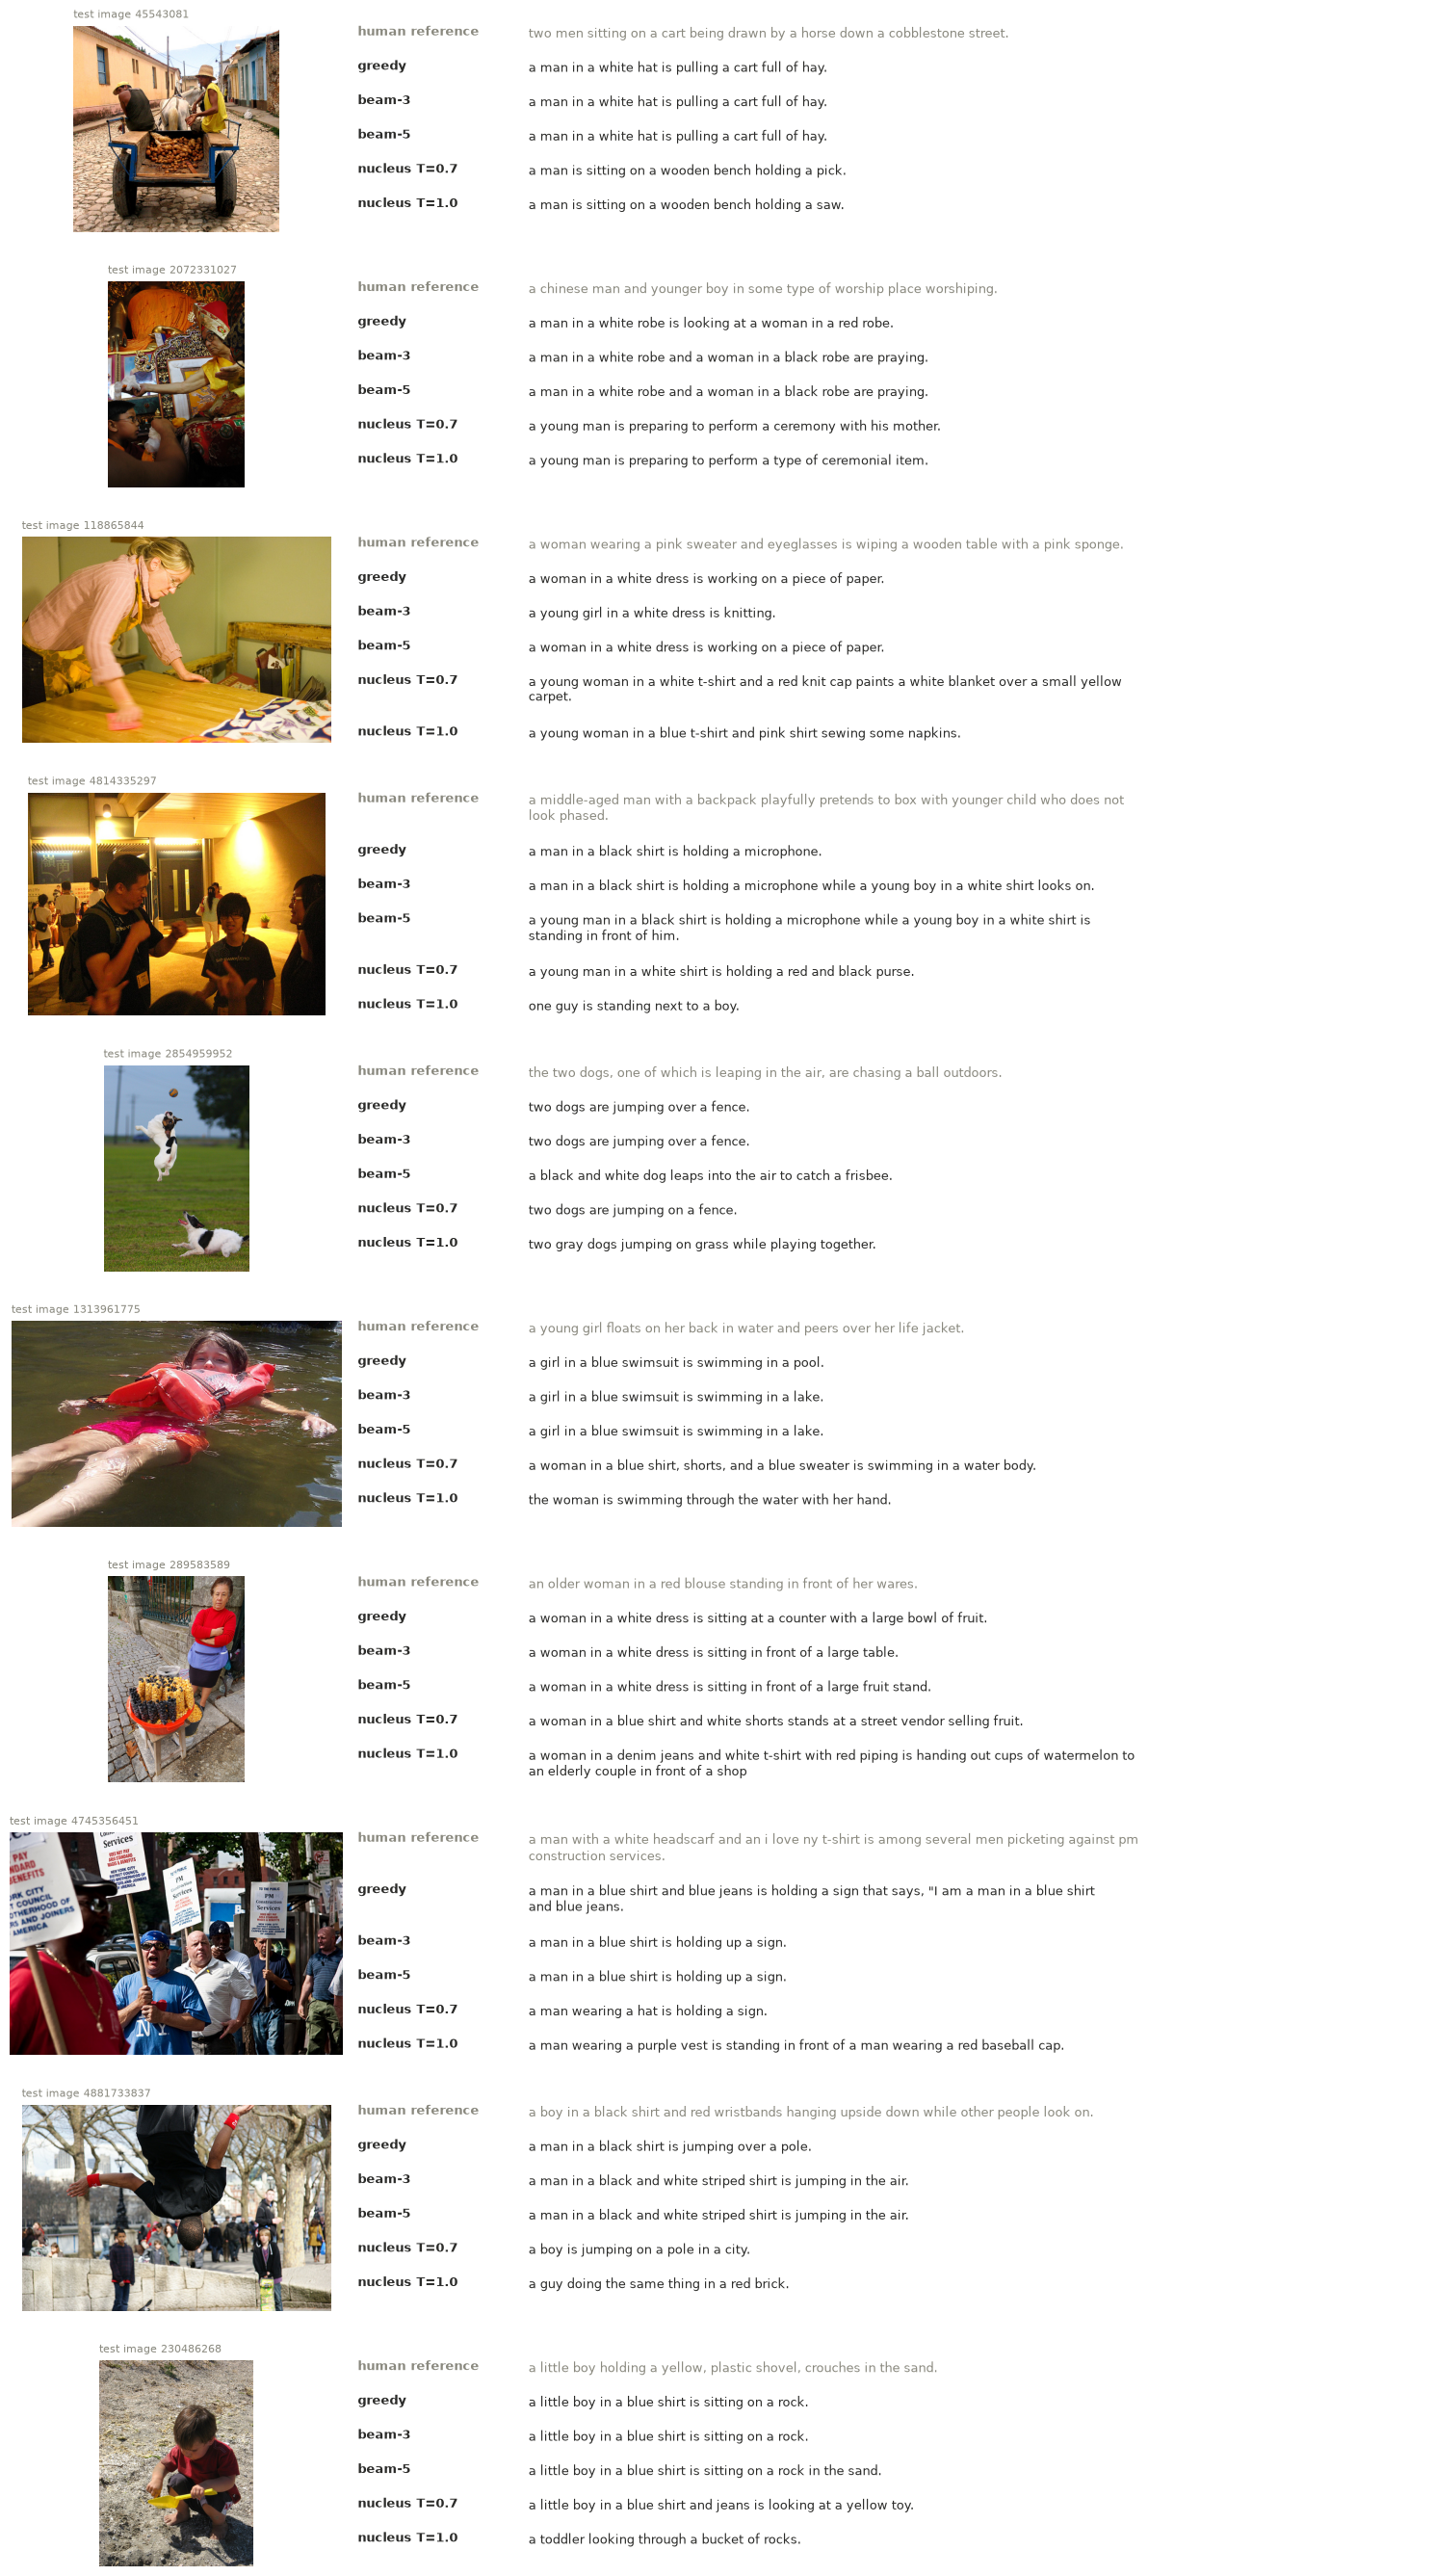

In [7]:
def wrap(s, width=95):
    return "\n".join(textwrap.wrap(s, width)) or "(empty)"

blocks = {iid: [("human reference", wrap(test_refs[iid][0]), MUTED)] +
                [(n, wrap(wide.loc[iid, n]), INK) for n in STRATEGIES] for iid in sample_ids}
# Row height follows the number of text lines, so long captions never run into the next image
slots = [max(sum(t.count("\n") + 1 for _, t, _ in blocks[iid]) + len(STRATEGIES), 12) for iid in sample_ids]
fig, axes = plt.subplots(len(sample_ids), 2, figsize=(15, 0.22 * sum(slots)),
                         gridspec_kw={"width_ratios": [1, 3.2], "height_ratios": slots})
for (ax_img, ax_txt), iid, n_slots in zip(axes, sample_ids, slots):
    ax_img.imshow(Image.open(IMG_DIR / f"{iid}.jpg")); ax_img.axis("off")
    ax_img.set_title(f"test image {iid}", fontsize=8, color=MUTED, loc="left")
    ax_txt.axis("off")
    y, step = 1.0, 1.0 / n_slots
    for label, text, color in blocks[iid]:
        ax_txt.text(0.0, y, label, fontsize=9, fontweight="bold", color=color, va="top", transform=ax_txt.transAxes)
        ax_txt.text(0.16, y, text, fontsize=9, color=color, va="top", linespacing=1.3, transform=ax_txt.transAxes)
        y -= step * (text.count("\n") + 2)
fig.tight_layout(h_pad=2.5); fig.savefig(RES_DIR / "decoding_samples.png", dpi=110, bbox_inches="tight"); plt.show()

**Diversity of sampling.** Deterministic strategies always return the same caption for an image. Nucleus sampling gives a different caption each time it is run. Here is one image decoded 5 times with different seeds:

In [8]:
iid = sample_ids[0]
e = embeddings_for([iid])
print("beam-5:", generate(e, "beam-5")[0], "\n")
for name in ["nucleus T=0.7", "nucleus T=1.0"]:
    print(name)
    for s in range(5):
        print("  -", generate(e, name, seed=s)[0])

/opt/anaconda3/envs/clipcap/lib/python3.11/site-packages/transformers/generation/utils.py:1485: UserWarning: Passing `no_repeat_ngram_size` with `inputs_embeds` and without `input_ids` to `generate` will apply n-gram constraints only to newly generated tokens, not to the prompt.
  warnings.warn(


beam-5: a man in a white hat is pulling a cart full of hay. 

nucleus T=0.7
  - a man is pulling a brown truck.


  - a man in a white shirt is pulling a red rowing wheel.
  - a man is sitting on a dirt bale and shoveling a large brown piece of food into the air.


  - a man with a cane and a pick is standing on a porch.
  - a man with a big white hat and a big red hat is riding a brown cart.
nucleus T=1.0


  - a man working with a van to clean up hay.
  - a white man stands in front of a black house with buckets.


  - a man is sitting down on a wheelbarrow and is pushing the big black cart in a disney wagon.
  - a boy sells a tractor that has been tied to a tree.


  - a man with a big tan hat and a big bundle of pineapples is shoveling logs down the road.


## 5. Quantitative comparison on the test split

Each strategy captions the first `N_EVAL` Karpathy test images (all 1,000 by default), scored as follows:

* **BLEU-1 / BLEU-4** (n-gram precision) and **CIDEr** (consensus with the 5 human captions, TF-IDF weighted), computed with the standard COCO caption scorers. Higher is better.
* **CLIP similarity:** cosine between the CLIP image embedding and the CLIP text embedding of the caption. Higher is better. It needs no references and is shown next to the human captions' score.
* **Length:** average number of words. Human captions are shown for comparison.
* **Diversity:** distinct-1 / distinct-2, the share of unique words / word pairs across all generated captions, plus the share of images that get a caption no other image got.
* **Repetition:** the share of captions that repeat a 3-word phrase, a sign of degenerate output.
* **Speed:** milliseconds per image on this GPU, measured with batches of 50.

In [9]:
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.cider.cider import Cider

clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE).eval()
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")


def words(s):
    return re.findall(r"[a-z0-9]+(?:'[a-z]+)?", s.lower())


@torch.no_grad()
def clip_text_emb(texts, bs=256):
    out = []
    for i in range(0, len(texts), bs):
        inp = clip_processor(text=texts[i:i + bs], return_tensors="pt", padding=True, truncation=True).to(DEVICE)
        t = clip_model.get_text_features(**inp)
        t = t if torch.is_tensor(t) else t.pooler_output
        out.append(nn.functional.normalize(t, dim=-1).cpu())
    return torch.cat(out)


def has_repeated_trigram(w):
    tri = list(zip(w, w[1:], w[2:]))
    return len(tri) != len(set(tri))


def score(ids, caps):
    gts = {i: [" ".join(words(r)) for r in test_refs[i]] for i in ids}
    res = {i: [" ".join(words(c)) or "a"] for i, c in zip(ids, caps)}
    bleu, _ = Bleu(4).compute_score(gts, res, verbose=0)
    cider, _ = Cider().compute_score(gts, res)
    toks = [words(c) for c in caps]
    uni = [w for t in toks for w in t]
    bi = [b for t in toks for b in zip(t, t[1:])]
    img = IMAGE_EMB[[emb_row[i] for i in ids]]
    clip_sim = (clip_text_emb(caps) * img).sum(-1).mean().item()
    counts = Counter(caps)
    return {"BLEU-1": bleu[0], "BLEU-4": bleu[3], "CIDEr": cider, "CLIP sim": clip_sim,
            "avg words": np.mean([len(t) for t in toks]),
            "distinct-1": len(set(uni)) / max(len(uni), 1), "distinct-2": len(set(bi)) / max(len(bi), 1),
            "unique captions": np.mean([counts[c] == 1 for c in caps]),
            "repeated 3-gram": np.mean([has_repeated_trigram(t) for t in toks])}


eval_ids = test_ids[:N_EVAL]
eval_emb = embeddings_for(eval_ids)
generated, metrics = {}, []
for name in STRATEGIES:
    caps, t0 = [], time.time()
    for i in tqdm(range(0, len(eval_ids), GEN_BATCH), desc=name, leave=False):
        caps += generate(eval_emb[i:i + GEN_BATCH], name, seed=SEED + i)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    ms = 1000 * (time.time() - t0) / len(eval_ids)
    generated[name] = caps
    metrics.append({"strategy": name, **score(eval_ids, caps), "ms / image": ms})
    print(f"{name:14s} done in {ms * len(eval_ids) / 1000:.0f}s")

# Reference point: how a held-out human caption scores against the other 4 (leave-one-out)
human_ids = [i for i in eval_ids if len(test_refs[i]) >= 5]
human_caps = [test_refs[i][0] for i in human_ids]
saved_refs = {i: test_refs[i] for i in human_ids}
for i in human_ids: test_refs[i] = saved_refs[i][1:]
human = score(human_ids, human_caps)
test_refs.update(saved_refs)
metrics.append({"strategy": "human (1 vs. other 4)", **human, "ms / image": np.nan})

metrics = pd.DataFrame(metrics).set_index("strategy")
metrics.round(3).to_csv(RES_DIR / "decoding_metrics.csv")
pd.DataFrame({"image_id": eval_ids, **generated}).to_csv(RES_DIR / "decoding_test_captions.csv", index=False)
metrics.style.format("{:.3f}").format("{:.1f}", subset=["avg words", "ms / image"])

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

greedy:   0%|          | 0/20 [00:00<?, ?it/s]

greedy         done in 13s


beam-3:   0%|          | 0/20 [00:00<?, ?it/s]

beam-3         done in 54s


beam-5:   0%|          | 0/20 [00:00<?, ?it/s]

... (2 outputs left out)

nucleus T=0.7  done in 20s


nucleus T=1.0:   0%|          | 0/20 [00:00<?, ?it/s]

nucleus T=1.0  done in 21s


,BLEU-1,BLEU-4,CIDEr,CLIP sim,avg words,distinct-1,distinct-2,unique captions,repeated 3-gram,ms / image
strategy,,,,,,,,,,
greedy,0.629,0.195,0.429,0.289,11.2,0.052,0.136,0.889,0.034,13.2
beam-3,0.640,0.208,0.470,0.290,11.2,0.050,0.131,0.853,0.000,53.8
beam-5,0.643,0.213,0.478,0.291,11.2,0.052,0.132,0.839,0.001,89.0
nucleus T=0.7,0.551,0.130,0.327,0.284,12.5,0.070,0.250,0.998,0.041,20.3
nucleus T=1.0,0.462,0.076,0.203,0.272,12.8,0.118,0.445,1.000,0.016,20.6
human (1 vs. other 4),0.503,0.150,0.535,0.323,18.2,0.133,0.500,1.000,0.027,nan


**Quality vs. diversity.** Each dot is one decoding strategy. The further right a dot is, the more the captions agree with the human references (CIDEr). The higher it is, the more varied the wording across images (distinct-2).

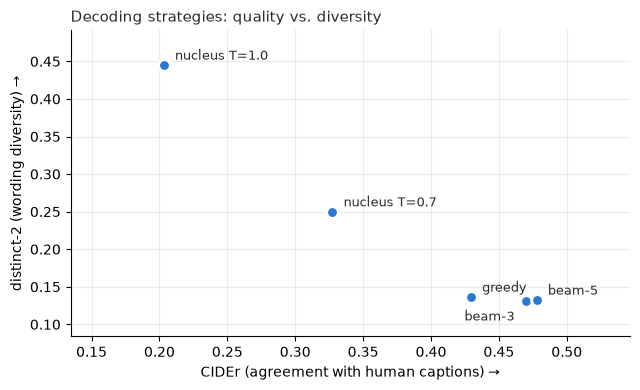

In [10]:
m = metrics.drop(index="human (1 vs. other 4)")
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(m.CIDEr, m["distinct-2"], s=70, color=BLUE, edgecolor="white", linewidth=2, zorder=3)
LABEL_POS = {"beam-3": ((-8, -14), "right")}       # beam-3 and beam-5 sit close together: put one label below-left
for name, r in m.iterrows():
    offset, ha = LABEL_POS.get(name, ((8, 4), "left"))
    ax.annotate(name, (r.CIDEr, r["distinct-2"]), xytext=offset, textcoords="offset points", ha=ha, fontsize=9, color=INK)
ax.set_xlabel("CIDEr (agreement with human captions) →"); ax.set_ylabel("distinct-2 (wording diversity) →")
ax.set_title("Decoding strategies: quality vs. diversity", loc="left", fontsize=11, color=INK)
ax.grid(alpha=0.25); ax.spines[["top", "right"]].set_visible(False)
ax.margins(x=0.25, y=0.15)
fig.tight_layout(); fig.savefig(RES_DIR / "quality_vs_diversity.png", dpi=150); plt.show()

## 6. Saved outputs

Everything is in `outputs/decoding/` (on Drive when run on Colab):

| File | Content |
|---|---|
| `train_log.csv`, `training_curve.png` | per-epoch train / val loss of the prototype |
| `decoding_samples.csv`, `decoding_samples.png` | 10 test images × 5 strategies, with a human reference |
| `decoding_metrics.csv` | the comparison table above |
| `decoding_test_captions.csv` | every generated test caption, per strategy |
| `quality_vs_diversity.png` | the CIDEr vs. distinct-2 plot |